**CUSTOMER SEGMENTATION**

**Problem Statement** - In this case study, your task is to identify major customer segments on a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.The company mainly sells unique all-occasion gifts. Many customers of the company are wholesalers.

**Data Attribute Information:**

**InvoiceNo**: Invoice number. Nominal, a 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation.


**StockCode**: Product (item) code. Nominal, a 5-digit integral number uniquely assigned to each distinct product.


**Description**: Product (item) name. Nominal.


**Quantity**: The quantities of each product (item) per transaction. Numeric.


**InvoiceDate**: Invoice Date and time. Numeric, the day and time when each transaction was generated.


**UnitPrice**: Unit price. Numeric, Product price per unit in sterling.


**CustomerID**: Customer number. Nominal, a 5-digit integral number uniquely assigned to each customer.


**Country**: Country name. Nominal, the name of the country where each customer resides.

In [ ]:
# Importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# will add libraries wherever libraries are required as per need

In [ ]:
# Load the Online Retail dataset

df = pd.read_csv('/content/Online Retail.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [ ]:
# Shape of dataset

df.shape

(541909, 8)

The Dataset has 541909 records and 8 columns

In [ ]:
df.info()    # All information related to dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


Categorical Features - InvoiceNo , StockCode , Description , CustomerID , Country

Numerical Features - Quantity , UnitPrice

Date time Object - Invoice Date

In [ ]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


Observations:

1. The Dataset contains few null values in Description and CustomerID feature, we will take care of them before EDA

2. The quantity and UnitPrice features show minimum as negative values, which means as per our understanding these are cancellation orders.

3. Seems like data is skewed because if you see Quantity and UnitPrice features, there is a huge difference in 75th Percentile and maximum value.


**Handling Duplicates and Missing Values in our dataset**

In [ ]:
df.duplicated().sum()

np.int64(5268)

In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
# Checking null values in Percentage

(df.isnull().sum()/df.shape[0])*100

,0
InvoiceNo,0.000000
StockCode,0.000000
Description,0.268311
Quantity,0.000000
InvoiceDate,0.000000
UnitPrice,0.000000
CustomerID,24.926694
Country,0.000000


In [ ]:
df.drop_duplicates(inplace = True)
df.dropna(inplace = True)

In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(401604, 8)

After dropping missing values and duplicates, dataset has 401K records and 8 columns

In [ ]:
# Now we will check for Cancelled Orders in our dataset

df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df[df['InvoiceNo'].str.startswith('C')]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/10 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/10 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/11 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/11 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/11 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/11 11:58,1.25,17315.0,United Kingdom


We identified 8,872 records with negative quantities, indicating potential cancelled or returned orders. Since our objective is to segment customers based on completed purchasing behavior, these records were excluded to avoid distorting purchase frequency and monetary value.

In [ ]:
# The Data without cancellation orders

cust_df = df[~(df['InvoiceNo'].str.startswith('C'))]

In [ ]:
cust_df.shape

(392732, 8)

After excluding cancelled orders from our dataset, we have 392732 records

In [ ]:
cust_df.describe()

,Quantity,UnitPrice,CustomerID
count,392732.000000,392732.000000,392732.000000
mean,13.153718,3.125596,15287.734822
std,181.588420,22.240725,1713.567773
min,1.000000,0.000000,12346.000000
25%,2.000000,1.250000,13955.000000
50%,6.000000,1.950000,15150.000000
75%,12.000000,3.750000,16791.000000
max,80995.000000,8142.750000,18287.000000


Observation:

1. No null values now in dataset
2. We can see in UnitPrice Feature  minimum value is showing as '0' but store cannot sell anything for free or 0 rupees
3. We will investigate these 0 rows and remove these records

In [ ]:
cust_df[cust_df['UnitPrice'] == 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12/5/10 14:02,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,12/16/10 14:36,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,12/21/10 13:45,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,1/6/11 16:41,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,1/6/11 16:41,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,1/13/11 15:10,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2/10/11 13:08,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,3/23/11 10:25,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,3/30/11 12:45,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,4/4/11 14:42,0.0,14410.0,United Kingdom


In [ ]:
new_cust_df = cust_df[cust_df['UnitPrice'] > 0 ]

In [ ]:
new_cust_df.shape

(392692, 8)

In [ ]:
new_cust_df.describe()

,Quantity,UnitPrice,CustomerID
count,392692.000000,392692.000000,392692.000000
mean,13.119702,3.125914,15287.843865
std,180.492832,22.241836,1713.539549
min,1.000000,0.001000,12346.000000
25%,2.000000,1.250000,13955.000000
50%,6.000000,1.950000,15150.000000
75%,12.000000,3.750000,16791.000000
max,80995.000000,8142.750000,18287.000000


Now our data is almost cleaned and we can move towards EDA but before that we will do some Feature Engineering

In [ ]:
# Coverting InvoiceDate Column into datetime format Column

new_cust_df['InvoiceDate'] = pd.to_datetime(new_cust_df['InvoiceDate'], format = "%m/%d/%y %H:%M")

In [ ]:
new_cust_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Creating some new features from InvoiceDate column

new_cust_df['Day'] = new_cust_df['InvoiceDate'].dt.day_name()
new_cust_df['Month'] = new_cust_df['InvoiceDate'].dt.month_name()
new_cust_df['Year'] = new_cust_df['InvoiceDate'].apply(lambda x: x.year)
new_cust_df['month_num'] = new_cust_df['InvoiceDate'].apply(lambda x: x.month)
new_cust_df['day_num'] = new_cust_df['InvoiceDate'].apply(lambda x: x.day)
new_cust_df['hour'] = new_cust_df['InvoiceDate'].apply(lambda x: x.hour)
new_cust_df['minute'] = new_cust_df['InvoiceDate'].apply(lambda x: x.minute)

In [ ]:
# Create Total Amount from UnitPrice and Quantity features

new_cust_df['Total Amount'] = new_cust_df['Quantity'] * new_cust_df['UnitPrice']
new_cust_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Day,Month,Year,month_num,day_num,hour,minute,Total Amount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,20.34


**Let's start with EDA now;**

1. Which Products are most and least sold ones ?

In [ ]:
malso = new_cust_df['Description'].value_counts().reset_index()
malso.rename(columns= {'Description': 'Description Name', 'count': 'Count'}, inplace = True)
malso.head()

,Description Name,Count
0,WHITE HANGING HEART T-LIGHT HOLDER,2016
1,REGENCY CAKESTAND 3 TIER,1713
2,JUMBO BAG RED RETROSPOT,1615
3,ASSORTED COLOUR BIRD ORNAMENT,1395
4,PARTY BUNTING,1389


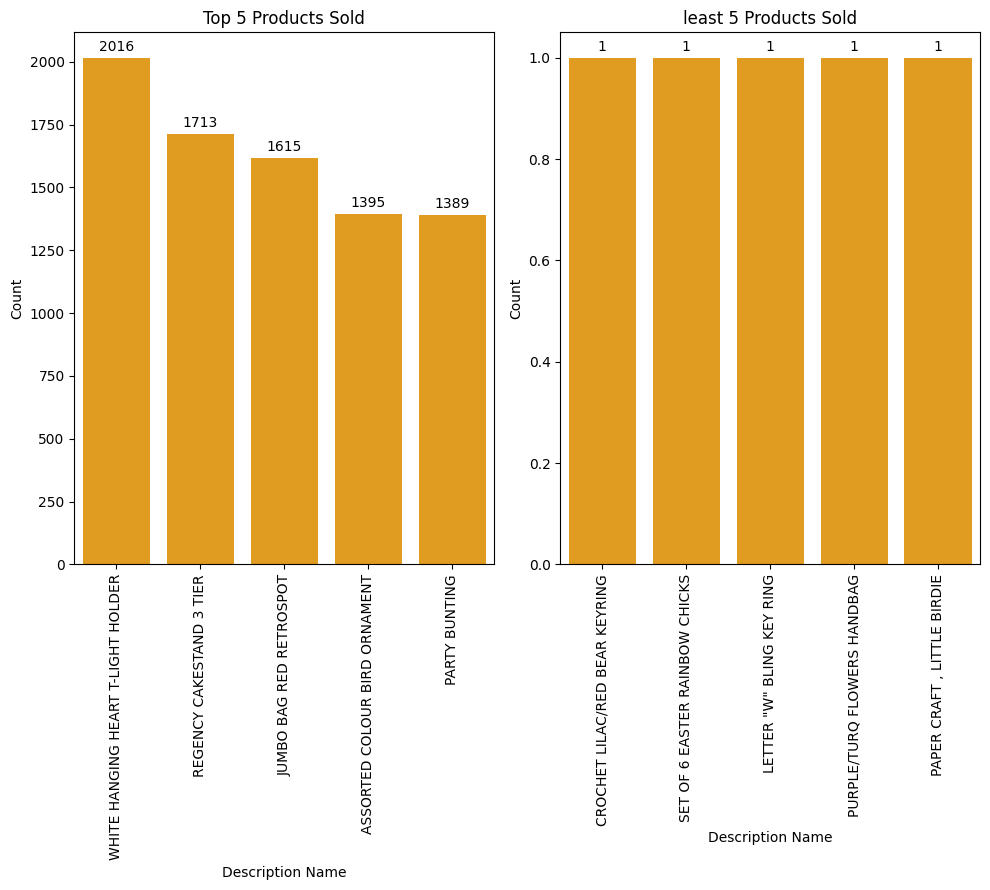

In [ ]:
fig, axes = plt.subplots(1,2, figsize = (10,9))

sns.barplot(data = malso.head(5), x = 'Description Name', y = 'Count', ax = axes[0], color= 'orange')
axes[0].set_title('Top 5 Products Sold')
axes[0].tick_params(axis = 'x', rotation = 90)

sns.barplot(data = malso.tail(5), x = 'Description Name', y = 'Count', ax = axes[1], color = 'orange')
axes[1].set_title('least 5 Products Sold')
axes[1].tick_params(axis = 'x', rotation = 90)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

**2. Which countries has the most and least number of customers?**

In [ ]:
malnoc = new_cust_df['Country'].value_counts().reset_index()
malnoc.head()

,Country,count
0,United Kingdom,349203
1,Germany,9025
2,France,8326
3,EIRE,7226
4,Spain,2479


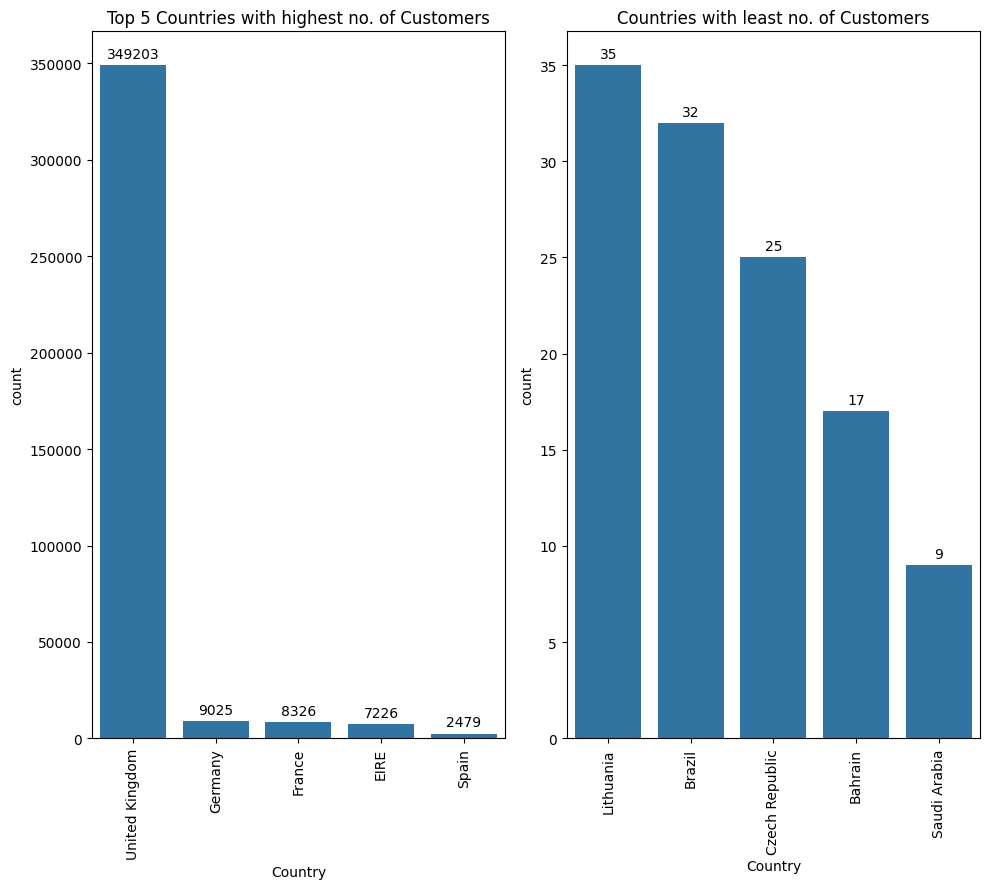

In [ ]:
fig, axes = plt.subplots(1,2, figsize = (10,9))

sns.barplot(data = malnoc.head(5), x = 'Country', y = 'count', ax = axes[0])
axes[0].set_title('Top 5 Countries with highest no. of Customers')
axes[0].tick_params(axis = 'x', rotation = 90)

sns.barplot(data = malnoc.tail(5), x = 'Country', y = 'count', ax = axes[1])
axes[1].set_title('Countries with least no. of Customers')
axes[1].tick_params(axis = 'x', rotation = 90)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()


In [ ]:
# Unique no. of customers in dataset

len(new_cust_df['CustomerID'].unique())

4338

4338 uniques customers present in our dataset

3. What is the order share of the top 10 customers?

In [ ]:
share_df = (new_cust_df['CustomerID'].value_counts()/sum(new_cust_df['CustomerID'].value_counts()) * 100).reset_index()
share_df.columns = ['Customer ID', 'Order Share']
share_df.head(10).cumsum()

,Customer ID,Order Share
0,17841.0,1.954713
1,32752.0,3.398592
2,46848.0,4.700121
3,59596.0,5.823648
4,74202.0,6.505353
5,89513.0,7.107861
6,104159.0,7.636519
7,117248.0,8.098459
8,130511.0,8.522965
9,144809.0,8.939831


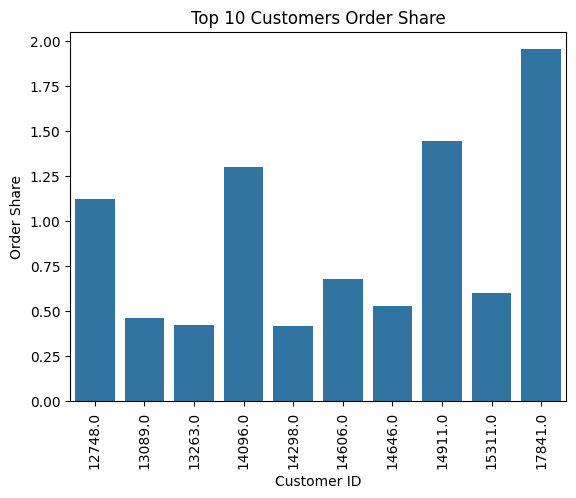

In [ ]:
sns.barplot(data = share_df.head(10), x = 'Customer ID', y = 'Order Share')
plt.title('Top 10 Customers Order Share')
plt.xticks(rotation = 90)
plt.show()

We can observe that only 10 customers out of 4338 unique customers are responsible for approx 9% of the total orders.

We can infer that these customers might be wholesalers.

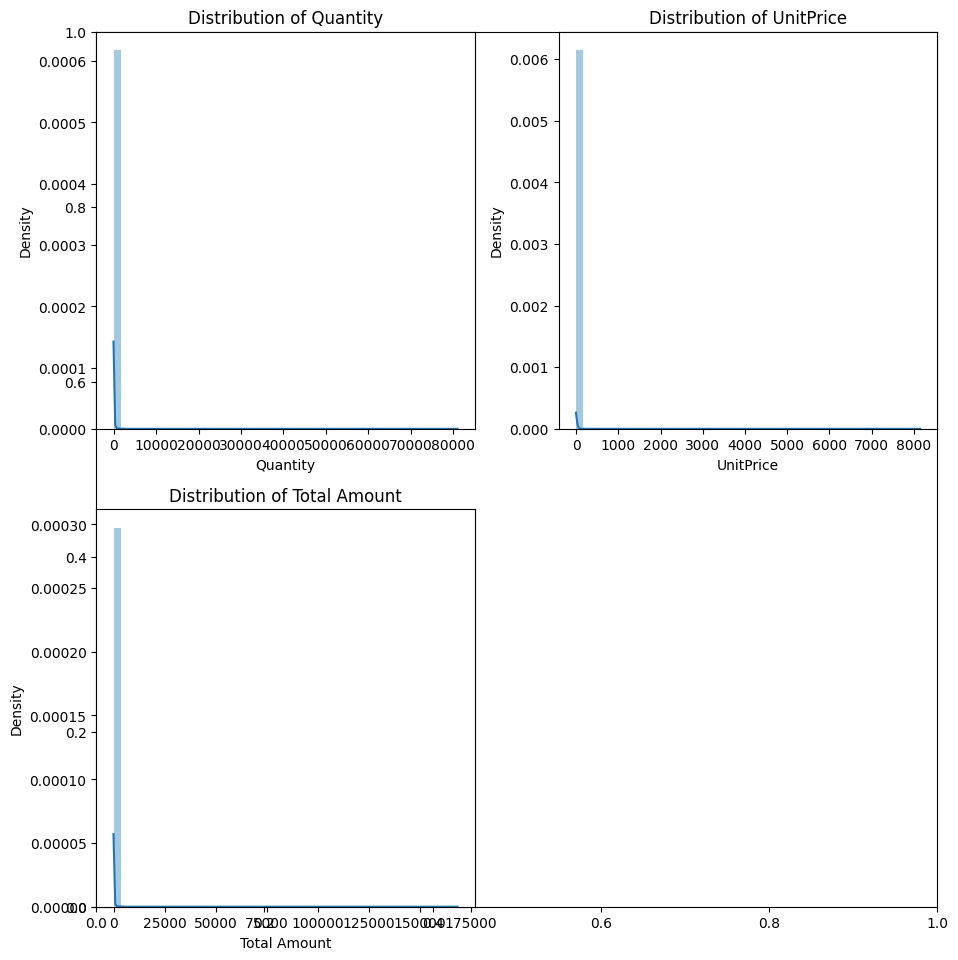

In [87]:
# let's check distribution of Numerical Feature

num_features = ['Quantity', 'UnitPrice', 'Total Amount']
plt.subplots(figsize = (10,10))
for col in num_features:
  plt.subplot(2,2, num_features.index(col)+1)
  sns.distplot(new_cust_df[col], kde = True)
  plt.title('Distribution of ' + col)
  plt.tight_layout()
plt.show()



The distribution of all the variables are heavily right skewed.

We will apply log transformation on these variables to make it less skewed.

We applied log transformation to reduce the right-skewness of RFM features, minimize the influence of extreme values, and improve distance-based customer clustering.

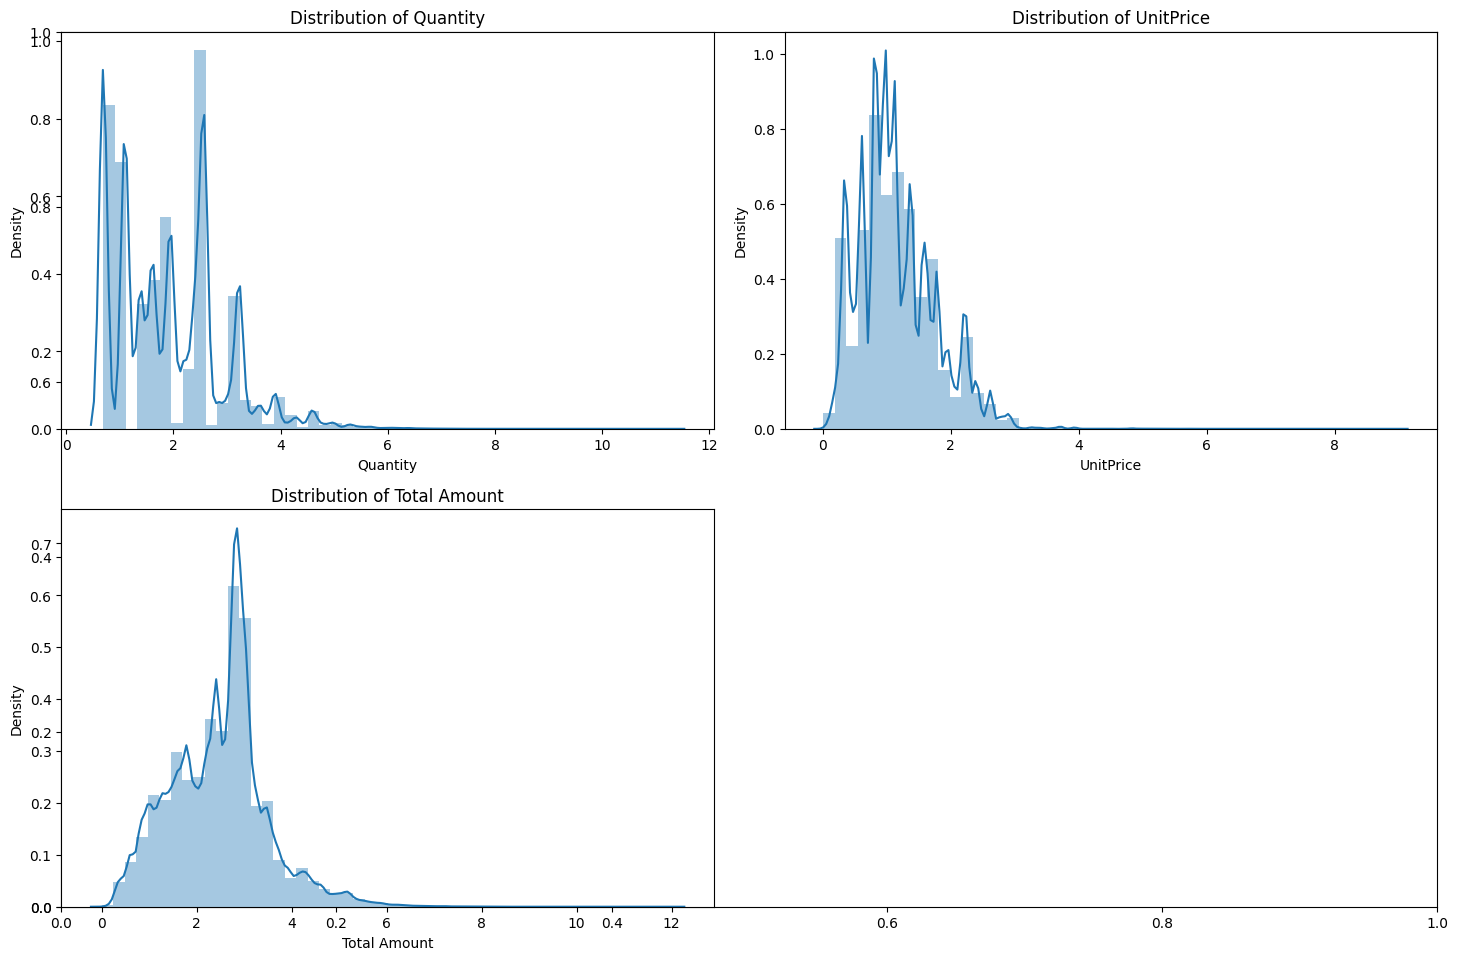

In [88]:
plt.subplots(figsize = (15,10))
for col in num_features:
  plt.subplot(2,2, num_features.index(col)+1)
  sns.distplot(np.log1p(new_cust_df[col]), kde = True)
  plt.title('Distribution of ' + col)
  plt.tight_layout()
plt.show()

The variables after log transformation are less skewed than before.

It isn't a normal distribution but somewhat close to that than before.

**4. Which day of the week had the most and the least number of purchases?**

In [90]:
day_df = new_cust_df['Day'].value_counts().reset_index()
day_df.head()

,Day,count
0,Thursday,79243
1,Wednesday,68040
2,Tuesday,65744
3,Monday,64231
4,Sunday,61212


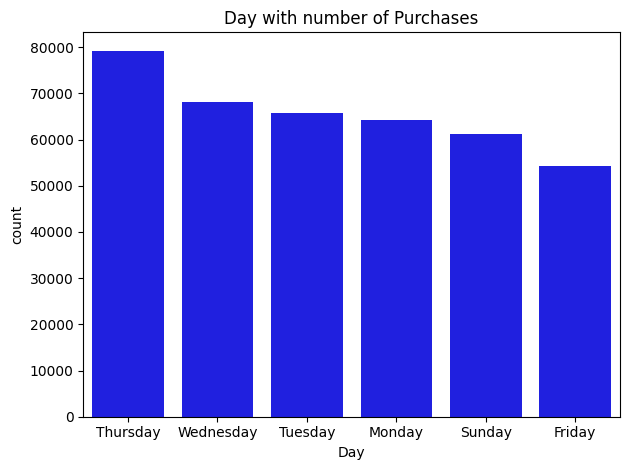

In [96]:

sns.barplot(data = day_df, x = 'Day', y = 'count', color = 'blue')
plt.title('Day with number of Purchases')


plt.tight_layout()
plt.show()

5. Which month had the most and the least number of purchases?

In [97]:
month_df = new_cust_df['Month'].value_counts().reset_index()
month_df.head()

,Month,count
0,November,63168
1,October,48793
2,December,42696
3,September,39669
4,May,28073


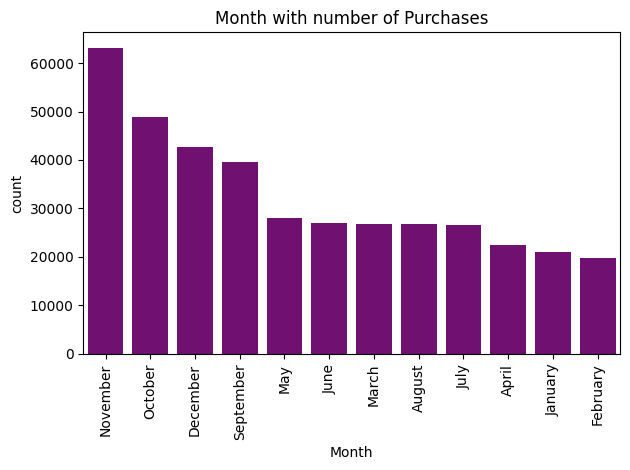

In [103]:
from numpy._core.fromnumeric import sort
sns.barplot(data = month_df, x = 'Month', y = 'count', color = 'purple')
plt.title('Month with number of Purchases')
plt.xticks(rotation = 90)


plt.tight_layout()
plt.show()

**6. Which hour of the day had the most and the least number of purchases?**

In [107]:
hour_df = new_cust_df['hour'].value_counts().reset_index()
hour_df.head()

,hour,count
0,12,70938
1,13,63019
2,14,53251
3,11,48365
4,15,44790


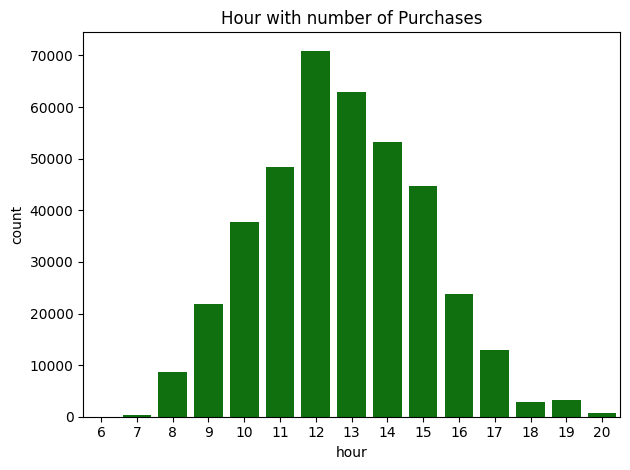

In [108]:
sns.barplot(data = hour_df, x = 'hour', y = 'count', color = 'green')
plt.title('Hour with number of Purchases')

plt.tight_layout()
plt.show()

Ok, let's group this hour (time) in three categories - Morning, Afternoon,  Evening

In [109]:
def categories(time):
  if (time >=6 and time <=12):
    return 'Morning'
  elif (time >=12 and time <=17):
    return 'Afternoon'
  else:
    return 'Evening'

In [110]:
# Apply function in dataset

new_cust_df['Time'] = new_cust_df['hour'].apply(categories)
new_cust_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Day,Month,Year,month_num,day_num,hour,minute,Total Amount,Time
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,15.30,Morning
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,20.34,Morning
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,22.00,Morning
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,20.34,Morning
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Wednesday,December,2010,12,1,8,26,20.34,Morning


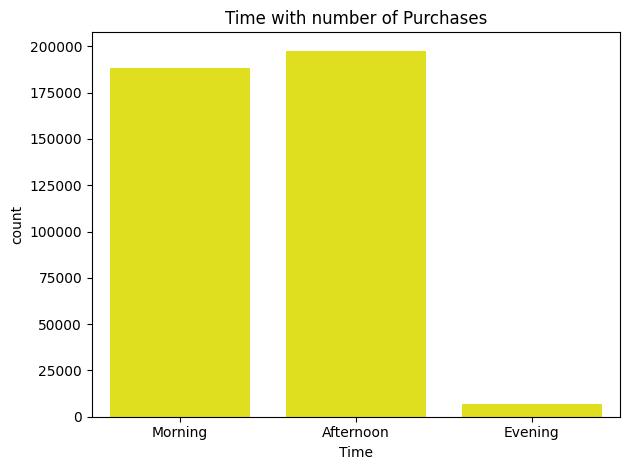

In [111]:
sns.countplot(data = new_cust_df, x = 'Time', color = 'yellow')
plt.title('Time with number of Purchases')

plt.tight_layout()
plt.show()

it is more clear that most of the purchases has occurred during the Afternoon followed by Morning and the least number of purchases during Evening.

**RFM Model Creation :**

**Recency**: How recently a customer has made a purchase

**Frequency**: How often a customer makes a purchase

**Monetary** Value: How much money a customer spends on purchases

Recency, frequency, monetary value is a marketing analysis tool used to identify a company's or an organization's best customers by measuring and analyzing spending habits.

RFM analysis numerically ranks a customer in each of these three categories, generally on a scale of 1 to 5 (the higher the number, the better the result). The "best" customer would receive a top score in every category.


These three RFM factors can be used to reasonably predict how likely (or unlikely) it is that a customer will do business again with a firm.

In [114]:
# As per problem statement and any analysis by far .. huge customers are from UK based Retail store. Hence we will implement on  UK based customers only for segmentaton


# Filter only UK based customers

uk_df = new_cust_df[new_cust_df['Country'] == 'United Kingdom']

In [115]:
uk_df.shape

(349203, 17)

In [118]:
# Calculating RFM Scores

# set latest date to '2011-12-10' as the last invoice date was '2011-12-09'
import datetime as dt

latest_date = dt.datetime(2011,12,10)

In [120]:
# Create RFM modelling score for each customers

rfm_df = uk_df.groupby('CustomerID').agg({'InvoiceDate': lambda x: (latest_date - x.max()).days,
                                           'InvoiceNo': lambda x:len(x),
                                           'Total Amount': lambda x: x.sum()
                                           })

In [122]:
# Convert invoice Date feature into int

rfm_df['InvoiceDate'] = rfm_df['InvoiceDate'].astype(int)

# Why do we convert it?
#In your RFM analysis, InvoiceDate no longer contains actual dates. It contains Recency values (number of days since the last purchase).

In [131]:
# rename columns to frequency, recency, monetary
rfm_df.rename(columns={'InvoiceDate': 'Recency', 'InvoiceNo': 'Frequency', 'Total Amount': 'Monetary'}, inplace=True)

In [132]:
rfm_df.reset_index().head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,1,77183.60
1,12747.0,2,103,4196.01
2,12748.0,1,4412,33053.19
3,12749.0,3,199,4090.88
4,12820.0,3,59,942.34


In [133]:
rfm_df.describe()

,Recency,Frequency,Monetary
count,3920.000000,3920.000000,3920.000000
mean,91.749235,89.082398,1858.424654
std,99.526935,214.034542,7478.631256
min,1.000000,1.000000,3.750000
25%,17.000000,17.000000,298.185000
50%,50.000000,40.000000,644.975000
75%,142.000000,98.000000,1571.285000
max,373.000000,7676.000000,259657.300000


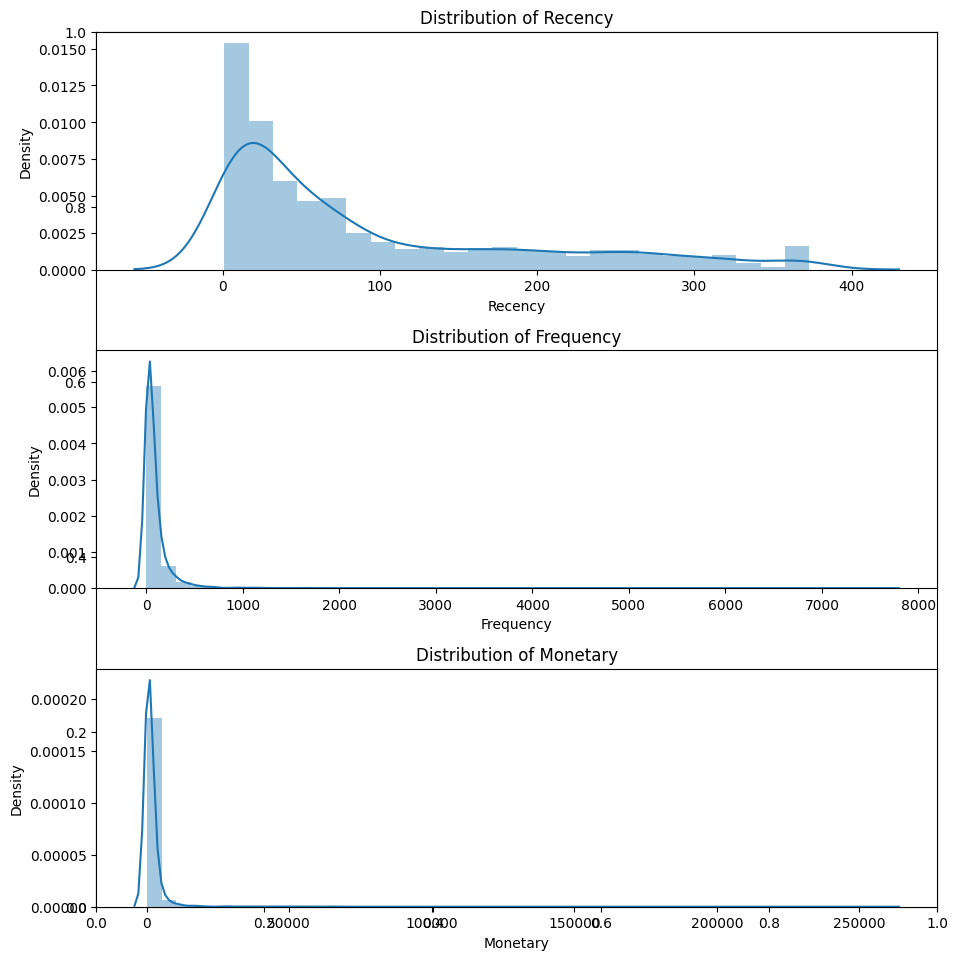

In [134]:
# Lets plot the distribution of RFM

plt.subplots(figsize = (10,10))
for col in rfm_df.columns:
  plt.subplot(3,1, rfm_df.columns.get_loc(col)+1)
  sns.distplot(rfm_df[col], kde = True)
  plt.title('Distribution of ' + col)
  plt.tight_layout()
plt.show()

Let's use Log Transformation:
to handle skewness, impact of outliers and Normalization of RFM data

In [139]:
# Treat negative and zero values

def treat(num):
  if num <= 0:
    return 1
  else:
    return num


# Apply this function to Recency and Monetary

rfm_df['Recency'] = [treat(x) for x in rfm_df['Recency']]
rfm_df['Monetary'] = [treat(x) for x in rfm_df['Monetary']]

# Apply Log transformation to RFM

log_df = rfm_df[['Recency', 'Frequency' ,'Monetary']].apply(np.log, axis = 1).round(3)

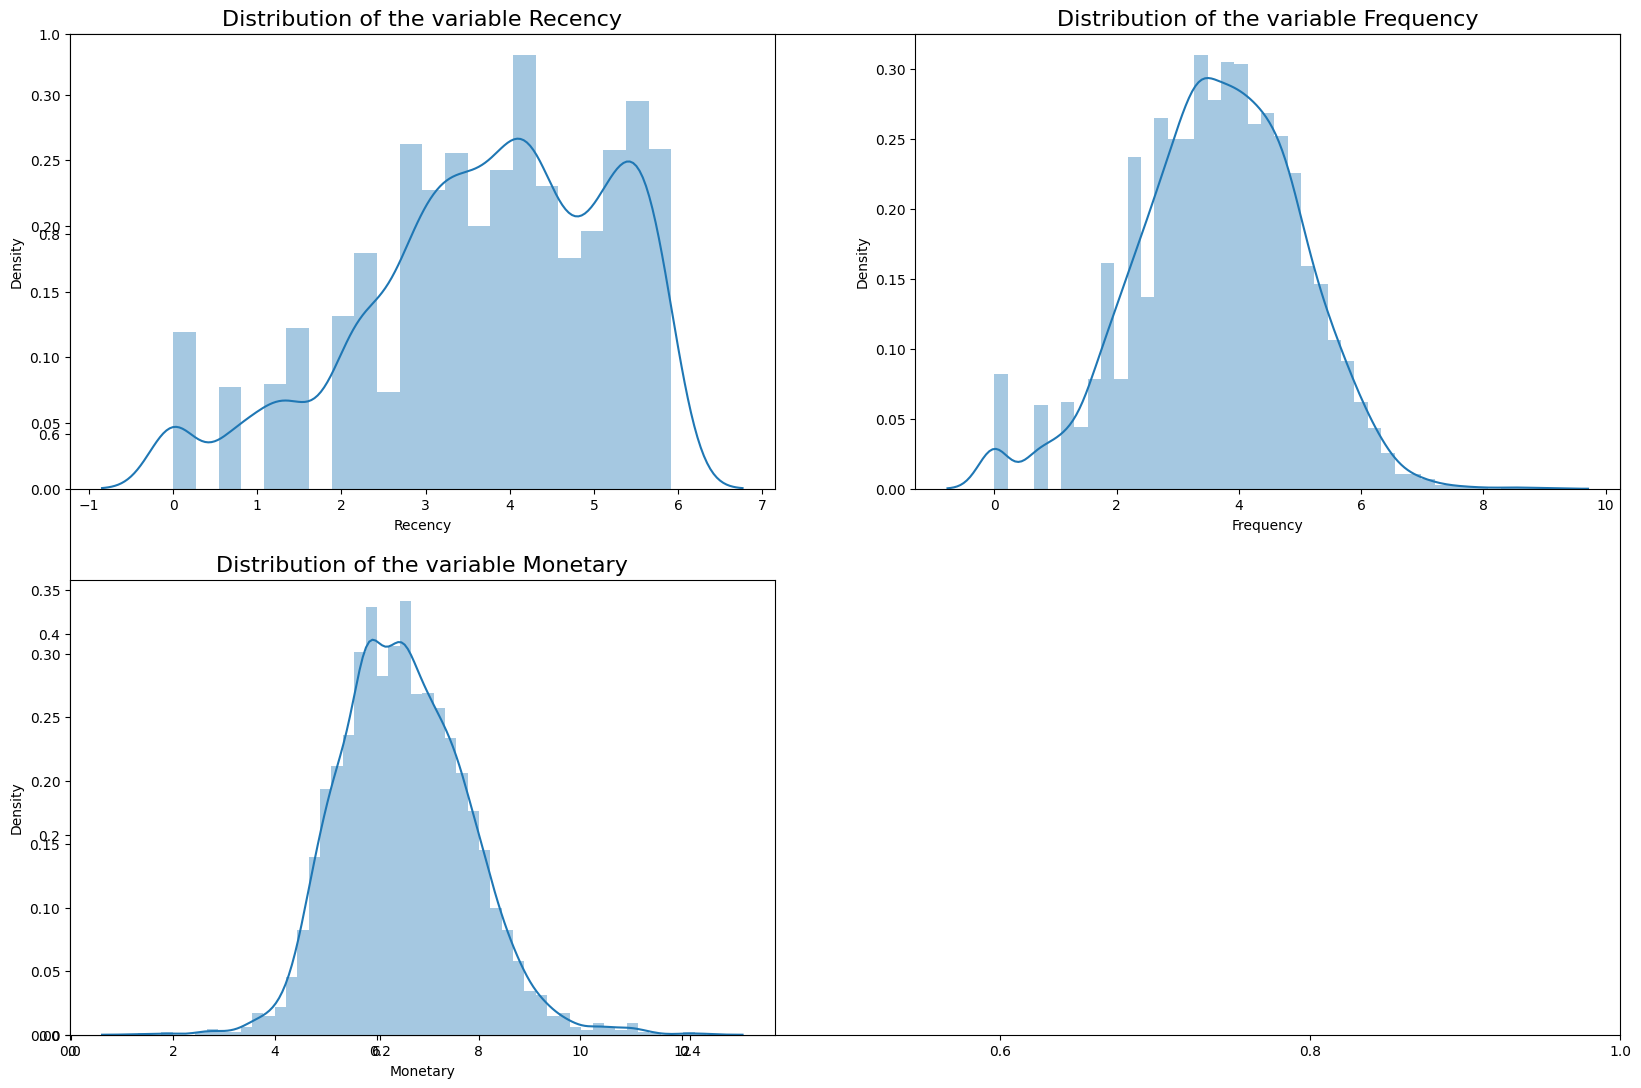

In [142]:
plt.subplots(figsize=(20,13))
count = 1
for feature in log_df:
  plt.subplot(2,2, count)
  sns.distplot(log_df[feature])
  plt.title(f"Distribution of the variable {feature}", fontsize=16)
  plt.xlabel(f"{feature}")
  plt.ylabel("Density")
  count += 1

The distribution of Recency, Frequency and Monetary values almost looks normal now

In [144]:
# apply log transformation on the original rfm dataframe

from math import log
import math

rfm_df['Recency_log'] = rfm_df['Recency'].apply(math.log)
rfm_df['Frequency_log'] = rfm_df['Frequency'].apply(math.log)
rfm_df['Monetary_log'] = rfm_df['Monetary'].apply(math.log)

In [145]:

rfm_df.head()

,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log
CustomerID,,,,,,
12346.0,325,1,77183.60,5.783825,0.000000,11.253942
12747.0,2,103,4196.01,0.693147,4.634729,8.341889
12748.0,1,4412,33053.19,0.000000,8.392083,10.405873
12749.0,3,199,4090.88,1.098612,5.293305,8.316515
12820.0,3,59,942.34,1.098612,4.077537,6.848366


In [146]:
features = ['Recency_log', 'Frequency_log', 'Monetary_log']

In [147]:
# Scaling our values

from sklearn.preprocessing import StandardScaler

x_features = rfm_df[features]
x = StandardScaler().fit_transform(x_features)

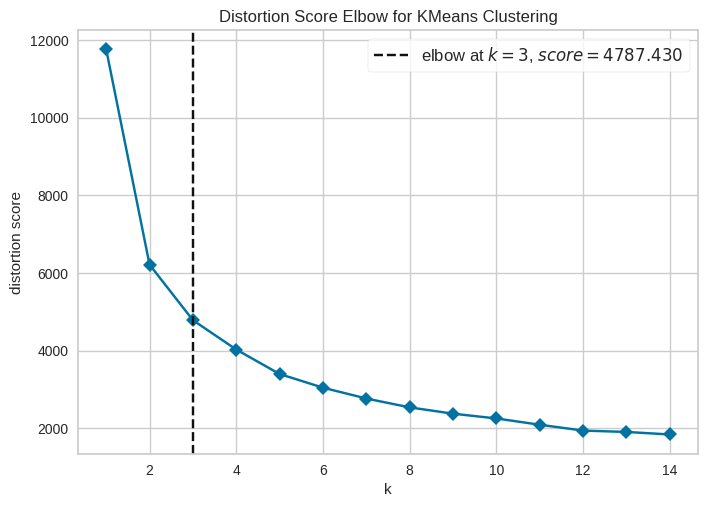

In [148]:
# now applying elbow method to find optimal no.of cluster

from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

inertia = {}
for k in range(1,15):
  km = KMeans(n_clusters = k, random_state = 42)
  km = km.fit(x)
  inertia = km.inertia_


# Plot elbow visulalization

visualizer = KElbowVisualizer(km, k = (1,15), metrics = 'distortion', timings = False )
visualizer.fit(x)
visualizer.poof()
plt.show()

No. of Optimal Cluster is 3

In [150]:
# Applying K means with opimal no. of Clusters

kmean = KMeans(n_clusters = 3)
kmean.fit(x)
y_km = kmean.predict(x)



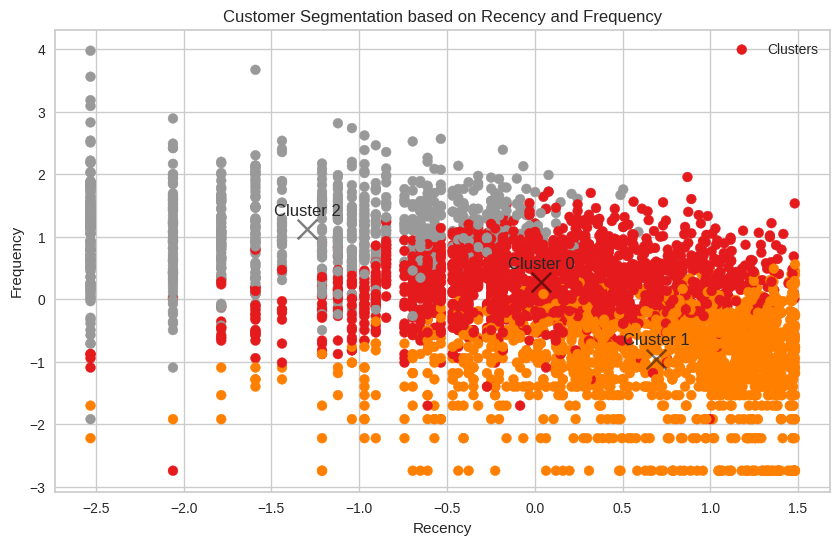

In [155]:
# Plot the clusters

plt.figure(figsize=(10, 6))
plt.title('Customer Segmentation based on Recency and Frequency')
plt.scatter(x[:,0], x[:,1], c=y_km, s=50, cmap='Set1', label='Clusters')

# Plot and annotate the centers
centers = kmean.cluster_centers_
plt.scatter(centers[:,0], centers[:,1], c='black', s=200, alpha=0.5, marker='x')


for i, center in enumerate(centers):
    plt.annotate(f'Cluster {i}', (center[0], center[1]), textcoords="offset points", xytext=(0,10), ha='center')

plt.xlabel('Recency')
plt.ylabel('Frequency')
plt.legend()
plt.show()

We can observe three clusters from the KMeans model applied on Recency, Frequency and Monetary data.

Interpreting the Clusters with the help of RFM Group:

Why is this required?
1. Understand customer behavior: Identify which customers purchase frequently, spend more, or haven't purchased recently.
2. Assign meaningful labels: Instead of Cluster 0, we can call it "High-Value Customers."
3. Business decisions: Helps businesses develop targeted marketing strategies.
4. Validate clustering results: Check whether clusters show meaningful differences in RFM characteristics.

In [157]:
# split the rfm values into quantiles
quantiles = rfm_df.quantile(q=[0.25,0.5,0.75])
quantiles = quantiles.to_dict()

In [159]:
# The purpose is to rank customers according to their purchasing behavior.

# function to create R, F, M segments
def RScore(x,p,d):
  if x <= d[p][0.25]:
    return 1
  elif x <= d[p][0.5]:
    return 2
  elif x <= d[p][0.75]:
    return 3
  else:
    return 4

def FnMScore(x,p,d):
  if x <= d[p][0.25]:
    return 4
  elif x <= d[p][0.5]:
    return 3
  elif x <= d[p][0.75]:
    return 2
  else:
    return 1

In [160]:
# calculate RFM segment values for each record
rfm_df['R'] = rfm_df['Recency'].apply(RScore, args=('Recency', quantiles, ))
rfm_df['F'] = rfm_df['Frequency'].apply(FnMScore, args=('Frequency', quantiles, ))
rfm_df['M'] = rfm_df['Monetary'].apply(FnMScore, args=('Monetary', quantiles, ))
rfm_df.reset_index().head()

,CustomerID,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log,R,F,M
0,12346.0,325,1,77183.60,5.783825,0.000000,11.253942,4,4,1
1,12747.0,2,103,4196.01,0.693147,4.634729,8.341889,1,1,1
2,12748.0,1,4412,33053.19,0.000000,8.392083,10.405873,1,1,1
3,12749.0,3,199,4090.88,1.098612,5.293305,8.316515,1,1,1
4,12820.0,3,59,942.34,1.098612,4.077537,6.848366,1,2,2


In [161]:
# add RFM group column
rfm_df['RFMGroup'] = rfm_df['R'].map(str) + rfm_df['F'].map(str) + rfm_df['M'].map(str)

# calculate RFM score from RFM group column
rfm_df['RFMScore'] = rfm_df[['R', 'F', 'M']].sum(axis=1)
rfm_df.reset_index().head()

,CustomerID,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log,R,F,M,RFMGroup,RFMScore
0,12346.0,325,1,77183.60,5.783825,0.000000,11.253942,4,4,1,441,9
1,12747.0,2,103,4196.01,0.693147,4.634729,8.341889,1,1,1,111,3
2,12748.0,1,4412,33053.19,0.000000,8.392083,10.405873,1,1,1,111,3
3,12749.0,3,199,4090.88,1.098612,5.293305,8.316515,1,1,1,111,3
4,12820.0,3,59,942.34,1.098612,4.077537,6.848366,1,2,2,122,5


In [163]:
# find the clusters for the observations in the dataset
rfm_df['Cluster'] = kmean.labels_
rfm_df.head()

,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log,R,F,M,RFMGroup,RFMScore,Cluster
CustomerID,,,,,,,,,,,,
12346.0,325,1,77183.60,5.783825,0.000000,11.253942,4,4,1,441,9,0
12747.0,2,103,4196.01,0.693147,4.634729,8.341889,1,1,1,111,3,2
12748.0,1,4412,33053.19,0.000000,8.392083,10.405873,1,1,1,111,3,2
12749.0,3,199,4090.88,1.098612,5.293305,8.316515,1,1,1,111,3,2
12820.0,3,59,942.34,1.098612,4.077537,6.848366,1,2,2,122,5,2


In [167]:
# Group by cluster label and calculate mean
cluster_averages = rfm_df.groupby('Cluster').mean(numeric_only=True)
cluster_averages

,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log,R,F,M,RFMScore
Cluster,,,,,,,,,,
0,67.826271,69.398910,1201.898797,3.786996,4.016057,6.772807,2.425545,2.153148,2.196126,6.774818
1,165.062932,15.125173,286.957725,4.757607,2.387100,5.412619,3.295989,3.628631,3.562241,10.486860
2,10.860097,258.740876,5942.271241,1.826311,5.151299,8.044293,1.205596,1.289538,1.242092,3.737226


**Cluster 0:**

Recency: Moderate (average around 68 days)

Frequency: Moderate (average around 69 transactions)

Monetary: Moderate (average around $1200)

Interpretation: Customers in this cluster can be seen as 'Potential Loyalists' or 'Promising' customers. They have a balanced score in all three RFM metrics. These customers have the potential to become more valuable if properly engaged. Tailored marketing strategies, loyalty programs, and incentives to increase their purchase frequency and value can be effective.


**Cluster 1:**

Recency: High (average around 165 days)

Frequency: Low (average around 15 transactions)

Monetary: Low (average around $286)

Interpretation: Customers in this cluster are likely to be 'At-Risk' or 'Lapsed' customers. They haven't made purchases recently, and when they did, they didn't do so very frequently and didn't spend much. These customers might have been one-time buyers or occasional shoppers. Engaging them with reactivation campaigns or exploring why they haven’t returned can be a strategic move.

**Cluster 2:**

Recency: Very Low (average around 11 days)

Frequency: Very High (average around 259 transactions)

Monetary: Very High (average around $5933)

Interpretation: This cluster represents your 'Champions' or 'Loyal' customers. They shop frequently, recently, and spend the most. They are the most valuable segment, likely to respond positively to new offers, up-sell and cross-sell opportunities. Maintaining their high engagement level is crucial, and they can also be targeted for feedback or as brand ambassadors.



**Overall Strategy:**

**Cluster 0 ('Champions/Loyal')**: Prioritize maintaining their high level of engagement. Offer exclusive deals, loyalty programs, and early access to new products. They can also be engaged in referral programs.



**Cluster 1 ('Potential Loyalists/Promising')**: Encourage them to visit and buy more often. Personalized communication, recommending products based on past purchases, and loyalty rewards can be effective.


**Cluster 2 ('At-Risk/Lapsed')**: Focus on re-engagement strategies. Understand their needs and reasons for not returning. Offer incentives or feedback surveys to encourage them to revisit and make purchases.





Thus, from our comparison table we can conclude that KMeans clustering on Recency, Frequency and Monetary data gives us the best result with the optimal number of clusters as 3. We can use this model to cluster our data in 3 segments and develop better marketing strategies.